# Hirschberg Linear-Space Alignment

Recover one complete global alignment while keeping rolling score rows.

Split the first sequence at its middle. Forward and reverse row scores identify an optimal split in the second sequence. Recursive calls recover the two halves. The plot counts score buffers, excluding output strings, recursion and Python slicing overhead.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import hirschberg, dp_align

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

GACTCTGAAG
GA-TCTGACG
Alignment score 13


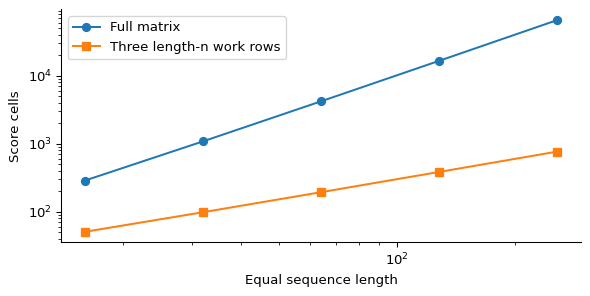

In [2]:
a, b = "GACTCTGAAG", "GATCTGACG"
x, y = hirschberg(a, b)
score = sum(-2 if "-" in (u, v) else 2 if u == v else -1 for u, v in zip(x, y))
assert x.replace("-", "") == a and y.replace("-", "") == b and score == dp_align(a, b)[0]
print(x)
print(y)
print("Alignment score", score)
n = np.array([16, 32, 64, 128, 256])
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.loglog(n, (n + 1) ** 2, "o-", label="Full matrix")
ax.loglog(n, 3 * (n + 1), "s-", label="Three length-n work rows")
ax.set(xlabel="Equal sequence length", ylabel="Score cells")
ax.legend()
plt.show()

## Interpreting the result

The alignment score agrees with full traceback. Different tie rules can produce a different optimal alignment.

## Exercise

Build two sequences with several equally good gap positions and check the score for each traceback.

## References

[Hirschberg, a linear-space alignment algorithm (1975)](https://doi.org/10.1145/360825.360861)

[Needleman and Wunsch, global alignment (1970)](https://doi.org/10.1016/0022-2836(70)90057-4)